<a href="https://colab.research.google.com/github/Hiarley007/Marchine_Learning/blob/main/Projeto_Academico(C%C3%B3pia).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📊 Projeto Acadêmico — Predição e Análise dos Níveis de Obesidade (Marco 1)
---

### 📝 Apresentação do Projeto
Este notebook apresenta o desenvolvimento do **Marco 1** do projeto acadêmico de **Machine Learning**. O objetivo é aplicar técnicas de análise exploratória, pré-processamento e modelagem preditiva para classificar os níveis de obesidade de indivíduos com base em dados físicos, histórico familiar e hábitos de vida.

---

### 📌 Ficha de Descrição do Dataset (Requisito 1)
* **Origem:** Repositório de Machine Learning da UCI (*Estimation of obesity levels based on eating habits and physical condition*).
* **Licença:** *Creative Commons Attribution 4.0 International* (CC BY 4.0) — uso liberado para fins acadêmicos e de pesquisa.
* **Número de Registros:** 2.111 linhas e 17 atributos originais.
* **Variável-Alvo (`NObeyesdad`):** Variável categórica multiclasse dividida em 7 níveis:
  1. `Insufficient_Weight` (Abaixo do peso)
  2. `Normal_Weight` (Peso normal)
  3. `Overweight_Level_I` (Sobrepeso Nível I)
  4. `Overweight_Level_II` (Sobrepeso Nível II)
  5. `Obesity_Type_I` (Obesidade Tipo I)
  6. `Obesity_Type_II` (Obesidade Tipo II)
  7. `Obesity_Type_III` (Obesidade Tipo III)

#### 📖 Dicionário de Atributos

| Atributo | Descrição / Sigla | Tipo de Dado |
| :--- | :--- | :--- |
| **Gender** | Gênero do indivíduo | Categórico Binário |
| **Age** | Idade em anos | Numérico Contínuo |
| **Height** | Altura em metros | Numérico Contínuo |
| **Weight** | Peso em quilogramas | Numérico Contínuo |
| **family_history_with_overweight** | Histórico familiar de sobrepeso | Categórico Binário |
| **FAVC** | Consumo frequente de alimentos calóricos (*Frequent consumption of high caloric food*) | Categórico Binário |
| **FCVC** | Frequência de consumo de vegetais (*Frequency of consumption of vegetables*) | Numérico Discreto |
| **NCP** | Número de refeições principais (*Number of main meals*) | Numérico Discreto |
| **CAEC** | Consumo de alimentos entre refeições (*Consumption of food between meals*) | Categórico Ordinal |
| **SMOKE** | Hábito de fumar | Categórico Binário |
| **CH2O** | Consumo diário de água | Numérico Contínuo |
| **SCC** | Monitoramento do consumo diário de calorias (*Calories consumption monitoring*) | Categórico Binário |
| **FAF** | Frequência de atividade física (*Physical activity frequency*) | Numérico Contínuo |
| **TUE** | Tempo de uso de dispositivos de tecnologia (*Time using technology devices*) | Numérico Contínuo |
| **CALC** | Frequência de consumo de álcool | Categórico Ordinal |
| **MTRANS** | Meio de transporte mais utilizado (*Transportation used*) | Categórico Nominal |
| **NObeyesdad** | **Target:** Classificação do Nível de Obesidade | Categórico (7 classes) |

---


### 👥 Informações Acadêmicas
* **Entrega:** Marco 1 — 18/09/2026
* **Instituição:** Centro Universitário IESB
* **Curso / Disciplina:** Aprendizagem de Máquinas - Marchine Learning
* **Autor(es):** Hiarley Rabêlo - 2514290067, Káthia Faria - 2514290053 e Letícia Rodrigues - 2514290010

# 🗂️ Etapa 01 - Preparação de conexão ao Google Drive

Conectamos ao Google Drive para os dados fiarem armazenados e quando abrirmos o Google Colab, ele já busca diretamente no Drive. Pois, os arquivos ficam salvos permanentemente na nuvem, evitando o trabalho de fazer upload do dataset toda vez que a sessão do Colab for encerrada.

In [ ]:
# Conectando google colab com o google drive

try:
    # O módulo google.colab SÓ existe dentro do Colab. É por isso que a
    # importação fica dentro de um try: se você um dia abrir este mesmo
    # notebook no seu computador, o código não quebra.
    from google.colab import drive

    # mount() "pendura" o seu Drive dentro da pasta /content/drive do
    # runtime. Depois disso, o Drive vira uma pasta comum para o Python.
    drive.mount('/content/drive')

    NO_COLAB = True
    print("Drive montado com sucesso.")

except ModuleNotFoundError:
    # Caímos aqui se não estamos no Colab. Não é erro, é só um aviso.
    NO_COLAB = False
    print("Não estamos no Colab: vou procurar o arquivo na pasta local.")

Mounted at /content/drive
Drive montado com sucesso.


### Caminho do Arquivo

Repare que separamos a **pasta** e **nome do arquivo** em duas variáveis. Parece exagero para um arquivo só, mas é o hábito certo: quando o projeto tiver vários arquivos na mesma pasta, você troca a pasta em um lugar só.

A função `os.path.exists()` confere se o caminho realmente aponta para algo que existe. Chamar isso **antes** de tentar ler economiza um erro feio e comprido.

In [ ]:
# ---------------------------------------------------------------------
# Objetivo desta célula: montar o caminho completo do arquivo e conferir
# se ele existe, ANTES de tentar ler.
#
# Variáveis criadas:
#   PASTA   (str) -> a pasta onde o arquivo está
#   ARQUIVO (str) -> o nome do arquivo
#   CAMINHO (str) -> os dois juntos, que é o que o pandas vai receber
# ---------------------------------------------------------------------

import os   # módulo de utilidades do sistema de arquivos

# Se você criou a pasta com outro nome, é ESTA linha que você altera.
PASTA = '/content/drive/MyDrive/Aprendizagem_de_maquinas/' if NO_COLAB else ''
ARQUIVO = 'ObesityDataSet_raw_and_data_sinthetic.csv'

# os.path.join junta pasta e arquivo cuidando das barras. É mais seguro
# do que somar textos com "+", que erra quando falta ou sobra uma barra.
CAMINHO = os.path.join(PASTA, ARQUIVO)

print("Caminho montado:", CAMINHO)

# exists() devolve True ou False. Nunca lança erro — só responde.
if os.path.exists(CAMINHO):
    print("Arquivo encontrado. Pode seguir.")
else:
    print("Arquivo NÃO encontrado. Confira o nome da pasta e do arquivo.")

Caminho montado: /content/drive/MyDrive/Aprendizagem_de_maquinas/ObesityDataSet_raw_and_data_sinthetic.csv
Arquivo encontrado. Pode seguir.


## Leitura Ingênua - Identificar as possivéis 3 falhas no arquivo.

Isso ocorre ao carregar um arquivo com o comando mais simples (pd.read_csv), confiando que os dados estão no formato perfeito sem antes verificar a estrutura do arquivo.

— O que quer dizer "ingênua"?

 Confia nos parâmetros padrão do sistema, ignorando que arquivos reais usam separadores, acentos, decimais e símbolos regionais ou contábeis.

In [ ]:
# -----------------------------------------------------------------------------
# Tentativa 01 - Fazer leitura do arquivo sem nenhum parâmetro.
#
# A biblioteca Pandas, irá assumir que o separador das colunas serão as vírgulas,
# pois é o que a sigla CSV promete. Vamos ver na prática.
#
# Envolve a chamada no try/except para o erro apresentar de maneira legível.
# -----------------------------------------------------------------------------
import pandas as pd

try:
  tentativa_01 = pd.read_csv(CAMINHO)
  print("Leu sem erro. Formato:", tentativa_01.shape)
except pd.errors.ParserError as erro:
  print("Erro de leitura. A mensagem foi:\n")
  print(erro)

Leu sem erro. Formato: (2111, 17)


## Diagnóstico 01: `Leu sem erro`

**Tentativa 01:** o arquivo foi lido com sucesso, sem apresentar erros. Isso ocorre porque o arquivo já se encontra dentro dos padrões de estrutura e formatação exigidos pela biblioteca Pandas.

No entanto, as demais tentativas serão realizadas para garantir uma **verificação completa da integridade e compatibilidade do arquivo**, identificando possíveis inconsistências que não foram detectadas durante a primeira leitura.

In [ ]:
# Tentativa 02 — Ajustando o Separador de Colunas (ex: Ponto e Vírgula ;)

tentativa_02 = pd.read_csv(CAMINHO, sep=";")
print("Formato lido:", tentativa_02.shape)

print("\nTipo de cada coluna:")
print(tentativa_02.dtypes)

Formato lido: (2111, 1)

Tipo de cada coluna:
Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad    object
dtype: object


## Diagnóstico 02: Falha Silenciosa de Ingestão

Tentativa 02: o arquivo foi lido sem retornar exceções no código, porém resultou nas dimensões (2111, 1). Isso caracteriza uma falha silenciosa de ingestão por aglutinação de colunas, pois a biblioteca não encontrou o separador informado (sep=";") e fundiu todas as 17 variáveis em uma única coluna gigante.

Esse diagnóstico comprova que a ausência de erros de leitura não garante a integridade da estrutura, confirmando que o caractere ponto e vírgula é inadequado para este conjunto de dados.

In [ ]:
# -----------------------------------------------------------------------------
# Tentativa 03 - Leitura explicitando o separador correto (vírgula ',').
#
# Após diagnosticar a falha da Tentativa 02, confirmamos que o delimitador
# correto do arquivo é a vírgula. Validamos o formato final (2.111 linhas e 17 colunas)
# e inspecionamos os tipos de dados (.dtypes) para garantir a ingestão perfeita.
# -----------------------------------------------------------------------------

tentativa_03 = pd.read_csv(CAMINHO, sep=",") # ou apenas pd.read_csv(CAMINHO)

print("Formato lido:", tentativa_03.shape)

print("\nTipo de cada coluna:")
print(tentativa_03.dtypes)

Formato lido: (2111, 17)

Tipo de cada coluna:
Gender                             object
Age                               float64
Height                            float64
Weight                            float64
family_history_with_overweight     object
FAVC                               object
FCVC                              float64
NCP                               float64
CAEC                               object
SMOKE                              object
CH2O                              float64
SCC                                object
FAF                               float64
TUE                               float64
CALC                               object
MTRANS                             object
NObeyesdad                         object
dtype: object


## Diagnóstico 03: Ingestão Bem-Sucedida e Validação Estrutural

Tentativa 03: o arquivo foi lido com sucesso absoluto, retornando as dimensões exatas de (2111, 17) ao utilizar a vírgula como delimitador (sep=","). A inspeção dos tipos de dados (dtypes) confirma a integridade da estrutura: as variáveis contínuas e numéricas foram mapeadas corretamente como float64, enquanto as variáveis categóricas e de texto foram identificadas como object.

Esse diagnóstico valida de forma definitiva que o arquivo está no padrão ideal, encerrando a etapa de testes de leitura e liberando a base de dados para a Análise Exploratória de Dados (EDA).

In [ ]:
# TENTATIVA 04 - VALIDAÇÃO DEFENSIVA DE TRAÇO CONTÁBIL / NULOS

tentativa_04 = pd.read_csv(CAMINHO, sep=",", na_values=[" - ", "—"])
print("Valores nulos encontrados após tratar traço contábil:")
print(tentativa_04.isnull().sum().sum())

Valores nulos encontrados após tratar traço contábil:
0


## Diagnóstico 04: Confirmação de Ausência de Símbolos Contábeis

Tentativa 04: A aplicação do parâmetro na_values=["-", "—"] manteve o formato (2111, 17) e confirmou 0 valores nulos na base. Isso consolida que o dataset é inteiramente limpo e padronizado no formato científico/estatístico, sem ruídos de formatação financeira.

## Codificação de Texto (Encoding)

É o "dicionário" que traduz letras, acentos e símbolos em código binário (zeros e uns) para o computador processar.

— **Principais Padrões:**

**UTF-8:** O padrão universal moderno (usado pelo Pandas e Python por padrão).

**ISO-8859-1 (Latin-1):** Padrão antigo, comum em arquivos criados no Windows ou Excel em português.

— **O que acontece quando o Encoding está errado:**

**Texto corrompido:** Palavras com acento ficam deformadas (ex: `São Paulo` vira `SÃ£o Paulo`), o que estraga filtros e gráficos.

**Erro no código:** A leitura do arquivo trava e gera o erro `UnicodeDecodeError`.

— **Como resolver no Pandas:** Informando o padrão correto no carregamento: pd.read_csv(`CAMINHO, encoding="latin1"`).

In [ ]:
# ---------------------------------------------------------------------
# Objetivo desta célula: mostrar o efeito de ler com a codificação
# errada. Repare no nome da primeira coluna nos dois casos.
# ---------------------------------------------------------------------

# Leitura com a codificação ERRADA (Latin-1 num arquivo UTF-8).
errada = pd.read_csv(CAMINHO, sep=';', decimal=',', encoding='latin-1')
print("Com encoding='latin-1' :", repr(errada.columns[0]))

# Leitura correta, descartando explicitamente a marca BOM.
certa = pd.read_csv(CAMINHO, sep=';', decimal=',', encoding='utf-8-sig')
print("Com encoding='utf-8-sig':", repr(certa.columns[0]))

Com encoding='latin-1' : 'Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad'
Com encoding='utf-8-sig': 'Gender,Age,Height,Weight,family_history_with_overweight,FAVC,FCVC,NCP,CAEC,SMOKE,CH2O,SCC,FAF,TUE,CALC,MTRANS,NObeyesdad'


## Leitura Definitiva - Todos os parâmetros em um só código.

A Leitura Definitiva é a consolidação técnica de todas as tentativas diagnósticas em uma única chamada validada, garantindo que o arquivo seja carregado sem erros visíveis ou silenciosos.

In [ ]:
df = pd.read_csv(
    CAMINHO,
    sep=',',
    encoding='utf-8',
    na_values=[' -   ', '-', ' - '])

# Validação final de garantia
print("Leitura definitiva concluída!")
print(f"Formato do DataFrame: {df.shape} (Esperado: 2111 linhas, 17 colunas")

Leitura definitiva concluída!
Formato do DataFrame: (2111, 17) (Esperado: 2111 linhas, 17 colunas


# 🗂️ Etapa 02 — Análise Exploratória e Transformação de Dados


Nesta etapa, realizamos o diagnóstico estatístico do conjunto de dados e preparamos suas variáveis para a futura modelagem preditiva. O trabalho divide-se em duas partes fundamentais:

1. **Engenharia de Atributos(Feature Engineering):** Criação da variável BMI (Índice de Massa Corporal) a partir de `Height` e `Weight`, fornecendo ao modelo uma métrica direta e alinhada às diretrizes da OMS.

2. **Estatística Descritiva:** Levantamento de medidas de tendência central (média, mediana e moda) e de dispersão (desvio padrão, amplitude e quartis) para compreender o comportamento, a simetria e a variabilidade dos dados numéricos e categóricos.

## Engenharia de Atributos (Feature Engineering)

 Criação da variável BMI (Índice de Massa Corporal) a partir de Height e Weight, fornecendo ao modelo uma métrica direta e alinhada às diretrizes da OMS

In [ ]:
import numpy as np

# =====================================================================
# FEATURE ENGINEERING: Criação da Variável BMI (Índice de Massa Corporal)
# =====================================================================

# 1. Cálculo da nova coluna utilizando a fórmula: Peso (kg) / Altura (m)²
# Como 'Height' já está em metros no dataset da UCI, a aplicação é direta.
# BMI == IMC -> Indíce de Massa Corporal
df['BMI'] = (df['Weight'] / (df['Height'] ** 2)).round(2)

# 2. Inspeção das primeiras linhas para validação visual
print("----- Visualização com base nas colunas envolvidas -----")
print(df[['Height', 'Weight', 'BMI', 'NObeyesdad']].head(10))

# 3. Teste de Sanidade - Garantia de Ausência de nulos ou divisões por zero.
nulos_bmi = df['BMI'].isnull().sum()
infinitos_bmi = np.isinf(df['BMI']).sum()

print(f"\nValores ausentes no BMI: {nulos_bmi}")
print(f"\nValores infinitos no BMI: {infinitos_bmi}")

----- Visualização com base nas colunas envolvidas -----
   Height  Weight    BMI           NObeyesdad
0    1.62    64.0  24.39        Normal_Weight
1    1.52    56.0  24.24        Normal_Weight
2    1.80    77.0  23.77        Normal_Weight
3    1.80    87.0  26.85   Overweight_Level_I
4    1.78    89.8  28.34  Overweight_Level_II
5    1.62    53.0  20.20        Normal_Weight
6    1.50    55.0  24.44        Normal_Weight
7    1.64    53.0  19.71        Normal_Weight
8    1.78    64.0  20.20        Normal_Weight
9    1.72    68.0  22.99        Normal_Weight

Valores ausentes no BMI: 0

Valores infinitos no BMI: 0


## 📊 Medidas de Tendência Central (Média, Mediana e Moda)


As **medidas de tendência central** são métricas estatísticas que sintetizam um conjunto de dados em um único valor representativo, indicando a localização do centro da sua distribuição. No contexto do projeto, essas métricas são fundamentais para diagnosticar o comportamento das variáveis antes da modelagem preditiva.

| Medida | Definição / Cálculo | Sensibilidade a *Outliers* | Aplicação Prática (EDA / ML) |
| :--- | :--- | :--- | :--- |
| **Média ($\bar{x}$)** | Soma de todos os valores dividida pelo número total de observações ($n$). <br> $\bar{x} = \frac{1}{n} \sum_{i=1}^{n} x_i$ | **Alta** (bastante sensível a valores extremos) | Adequada para variáveis numéricas contínuas com distribuição simétrica. |
| **Mediana** | Valor central do conjunto de dados após a ordenação em rol (divide a amostra em 50% abaixo e 50% acima). | **Baixa** (robusta contra valores discrepantes) | Indicada para variáveis numéricas com assimetria ou presença de *outliers*. |
| **Moda** | Valor ou categoria que ocorre com maior frequência absoluta na amostra. | **Nula** | Utilizada para variáveis categóricas (textuais) e identificação de padrões predominantes. |

### 🧮 Média

Soma de todos os valores dividida pelo número total de observações ( n ).

In [ ]:
# Medida de Tedência Central - Média

# A análise escolhida para realizar esse cálculo é a seguinte:
# Média do BMI e dos hábitos alimentares com variavéis numéricas agrupadas
# por classe de Obesidade.

# Variavéis:
# NObeyesdad -> Nivéis de Obesidade;
# BMI        -> Indíce de Massa Corporal;
# FAF        -> Frequência de Atividade Física;
# CH2O       -> Consumo de Água;
# FCVC       -> Consumo de Vegetais.

df.groupby('NObeyesdad')[['BMI', 'FAF', 'CH2O', 'FCVC']].mean().round(2)

,BMI,FAF,CH2O,FCVC
NObeyesdad,,,,
Insufficient_Weight,17.40,1.25,1.87,2.48
Normal_Weight,22.01,1.25,1.85,2.33
Obesity_Type_I,32.26,0.99,2.11,2.19
Obesity_Type_II,36.72,0.97,1.88,2.39
Obesity_Type_III,42.27,0.66,2.21,3.00
Overweight_Level_I,25.99,1.06,2.06,2.26
Overweight_Level_II,28.22,0.96,2.03,2.26


#### Interpretativo dos Hábitos por Classe de Obesidade (`NObeyesdad`)

A análise das médias das variáveis numéricas de hábitos em relação às categorias de peso revelou padrões comportamentais e fisiológicos relevantes:

1. **Relação Inversa entre Atividade Física (`FAF`) e Obesidade:**
   * Observa-se que a frequência de exercício físico é maior no grupo de **Peso Insuficiente** (`FAF = 1.25`) e de **Peso Normal** (`FAF = 1.25`), caindo progressivamente até atingir o menor nível no grupo **Obesidade Tipo III** (`FAF = 0.66`).

2. **Déficit Calórico no Peso Insuficiente:**
   * A combinação de **alta atividade física** (`FAF = 1.25`) com **alto consumo de vegetais** (`FCVC = 2.48`) no grupo de *Peso Insuficiente* explica o baixo IMC médio (`BMI = 17.40`). A alta queima calórica aliada a alimentos de baixa densidade energética favorece a manutenção do peso abaixo do ideal.

3. **Hidratação (`CH2O`) e Necessidade Corporal:**
   * O consumo de água é menor nos grupos de peso normal e insuficiente (1.85 L) e atinge suas maiores médias nos grupos de **Obesidade Tipo I e III** (~2.11 L a 2.21 L), acompanhando a maior necessidade hídrica associada a massas corporais mais elevadas.

4. **Padrão em Obesidade Severa (`Obesity_Type_III`):**
   * Apresenta o maior valor para consumo de vegetais (`FCVC = 3.00`) e o menor para exercícios (`FAF = 0.66`). Isso sugere possíveis tentativas de controle alimentar por dietas restritivas em quadros de obesidade avançada, aliados à limitação de mobilidade física.

### ✂️ Mediana

Valor central do conjunto de dados após a ordenação em rol (divide a amostra em 50% abaixo e 50% acima).

In [ ]:
# Medida de Tedência Central - Mediana

# A análise escolhida para realizar esse cálculo é a seguinte:
# Mediana do BMI e dos hábitos alimentares com variavéis numéricas agrupadas
# por classe de Obesidade.

# Variavéis:
# NObeyesdad -> Nivéis de Obesidade;
# BMI        -> Indíce de Massa Corporal;
# FAF        -> Frequência de Atividade Física;
# CH2O       -> Consumo de Água;
# FCVC       -> Consumo de Vegetais.

df.groupby('NObeyesdad')[['BMI', 'FAF', 'CH2O', 'FCVC']].median().round(2)

,BMI,FAF,CH2O,FCVC
NObeyesdad,,,,
Insufficient_Weight,17.55,1.34,2.00,2.71
Normal_Weight,22.15,1.00,2.00,2.00
Obesity_Type_I,32.20,0.99,2.01,2.00
Obesity_Type_II,36.42,0.99,2.00,2.43
Obesity_Type_III,41.94,0.22,2.43,3.00
Overweight_Level_I,25.98,1.00,2.00,2.00
Overweight_Level_II,28.16,0.96,2.00,2.00


#### **Análise da Mediana e Comparativo de Tendência Central**

A forte proximidade entre os valores de **Média** e **Mediana** demonstra estabilidade estatística e ausência de *outliers* severos dentro de cada grupo de peso (`NObeyesdad`).

**Principais Insights Identificados:**

1. **Padrão de Peso Insuficiente (`Insufficient_Weight`):**
   * Apresenta a maior mediana de atividade física do dataset (`FAF = 1.34`) e alto consumo de vegetais (`FCVC = 2.71`).
   * **Diagnóstico:** Confirma um estado de alto gasto calórico combinado a uma dieta de baixa densidade energética, sustentando o IMC reduzido (`BMI = 17.55`).

2. **Padrão de Obesidade Severa (`Obesity_Type_III`):**
   * **Sedentarismo Crítico:** A mediana de atividade física despenca para `FAF = 0.22`, indicando que a grande maioria dos indivíduos dessa classe não pratica exercícios regularmente.
   * **Consumo Alimentar:** A mediana de vegetais atinge o teto da escala (`FCVC = 3.00`), o que pode indicar tentativas de dietas restritivas ou o viés de autorrelato característico do dataset.

### 🔝 Moda

Valor ou categoria que ocorre com maior frequência absoluta na amostra.

In [ ]:
# Medida de Tedência Central - Moda

# A análise escolhida para realizar esse cálculo é a seguinte:
# Moda dos hábitos de variavéis de números contínuos por classes de
# variavéis categóricas.

# Variavéis:
# SMOKE      -> Hábito de Fumar;
# FAF        -> Frenquência de Atividade Física;
# CALC       -> Consumo de Álcool
# NObeyesdad -> Nivéis de Obesidade;

# df.groupby(fator)[['Weight', 'Age']] agrupa os dados pela variável analisada e
# seleciona Peso e Idade.
# .apply(lambda x: x.mode().iloc[0] if not x.mode().empty else None) é o comando
# utilizado para extrair de forma segura o valor mais frequente — a moda
# estatística — de cada grupo (evitando erros caso esteja vazio).
#  .round(2) padroniza o resultado final para duas casas decimais.

import pandas as pd

# Lista das variáveis de agrupamento (fatores)
fatores = ['SMOKE', 'FAF', 'CALC', 'NObeyesdad']

# Dicionário para armazenar as tabelas de resultados
resultados_moda = {}

print("=" * 65)
print("📊 CÁLCULO DA MODA DE WEIGHT (PESO) E AGE (IDADE) POR FATOR")
print("=" * 65 + "\n")

# Loop principal para calcular a moda das variáveis por cada fator
for fator in fatores:
    print(f"🔍 [FATOR] Moda de Weight e Age agrupada por: {fator}")

    # Cálculo da moda para Weight e Age
    tabela_moda = (
        df.groupby(fator)[['Weight', 'Age']]
          .apply(lambda x: x.mode().iloc[0] if not x.mode().empty else None)
          .round(2)
    )

    # Renomeia as colunas para clareza na visualização
    tabela_moda.columns = ['Moda_Peso_kg', 'Moda_Idade_anos']

    # Exibe a tabela formatada no Colab
    display(tabela_moda)

    # Guarda o DataFrame no dicionário caso queira usar depois
    resultados_moda[fator] = tabela_moda

    print("\n" + "-" * 65 + "\n")

📊 CÁLCULO DA MODA DE WEIGHT (PESO) E AGE (IDADE) POR FATOR

🔍 [FATOR] Moda de Weight e Age agrupada por: SMOKE


,Moda_Peso_kg,Moda_Idade_anos
SMOKE,,
no,80.0,18.0
yes,60.0,21.0



-----------------------------------------------------------------

🔍 [FATOR] Moda de Weight e Age agrupada por: FAF


,Moda_Peso_kg,Moda_Idade_anos
FAF,,
0.000000,42.00,26.00
0.000096,109.98,25.96
0.000272,110.00,25.96
0.000454,110.17,25.99
0.001015,109.98,25.95
...,...,...
2.939733,80.00,21.71
2.971832,78.37,21.01
2.998981,101.78,39.76



-----------------------------------------------------------------

🔍 [FATOR] Moda de Weight e Age agrupada por: CALC


,Moda_Peso_kg,Moda_Idade_anos
CALC,,
Always,65.0,21.0
Frequently,78.0,23.0
Sometimes,70.0,26.0
no,80.0,18.0



-----------------------------------------------------------------

🔍 [FATOR] Moda de Weight e Age agrupada por: NObeyesdad


,Moda_Peso_kg,Moda_Idade_anos
NObeyesdad,,
Insufficient_Weight,50.0,18.0
Normal_Weight,60.0,21.0
Obesity_Type_I,80.0,18.0
Obesity_Type_II,120.0,41.0
Obesity_Type_III,102.0,26.0
Overweight_Level_I,70.0,21.0
Overweight_Level_II,80.0,23.0



-----------------------------------------------------------------



#### 📊 Análise Exploratória Baseada Estritamente nos Dados

---

### 🚬 1. Hábito de Fumar (`SMOKE`)
* **Observação dos Dados:** A moda de peso do grupo que **não fuma** é de **80,0 kg** (com idade modal de **18 anos**), enquanto o grupo que **fuma** apresenta moda de peso de **60,0 kg** (com idade modal de **21 anos**).
* **Diagnóstico Estatístico:** Registra-se uma diferença de **20,0 kg** a mais na moda ponderal do grupo não fumante em relação ao grupo fumante, com ambas as modas etárias concentradas no início da idade adulta (18 a 21 anos).

---

### 🏃 2. Frequência de Atividade Física (`FAF`)
* **Observação dos Dados:** A variável apresenta distribuição contínua entre $0{,}0$ e $3{,}0$.
  * Na inatividade ($\text{FAF} \approx 0$), o menor peso modal registrado é de **42,0 kg** (aos **26 anos**), enquanto os demais registros de inatividade concentram pesos modais elevados, entre **109,0 kg e 110,0 kg** (também na faixa dos **26 anos**).
  * Nos níveis com prática ativa ($\text{FAF} \approx 3$), observam-se pesos modais entre **75,0 kg e 80,0 kg** concentrados na faixa etária de **21 anos**.
  * Em valores intermediários/altos de FAF ($\approx 2{,}99$), registram-se modas de peso entre **101,0 kg e 103,0 kg** em faixas etárias mais elevadas (**38 a 39 anos**).
* **Diagnóstico Estatístico:** Os dados apontam variabilidade tanto de peso quanto de faixa etária ao longo da escala de FAF. Destaca-se a presença de modas de peso elevadas (acima de 100 kg) associadas a idades modais mais avançadas (38-39 anos) em níveis elevados de FAF.

---

### 🍺 3. Consumo de Álcool (`CALC`)
* **Observação dos Dados:** Indivíduos que declaram não consumir álcool (`no`) registram a maior moda de peso (**80,0 kg**) combinada à menor idade modal (**18 anos**).
* **Diagnóstico Estatístico:** A maior idade modal registrada nesta variável é de **26 anos**, pertencente à categoria de consumo ocasional (`Sometimes`), cuja moda de peso é de **70,0 kg**.

---

### ⚖️ 4. Nível de Obesidade (`NObeyesdad`)
* **Observação dos Dados:** O nível `Obesity_Type_II` destaca-se por apresentar a maior moda de peso (**120,0 kg**) e a maior idade modal (**41,0 anos**).
* **Diagnóstico Estatístico e Próximo Passo:** Para validar o impacto real dessa observação na amostra global, faz-se necessário mensurar a representatividade volumétrica (porcentagem e contagem absoluta) de cada classe de `NObeyesdad` no dataset.

In [ ]:
# Tabela de Frequência Absoluta (Contagem) e Relativa (%) para NObeyesdad
freq_target = pd.DataFrame({
    'Contagem_Absoluta': df['NObeyesdad'].value_counts(),
    'Porcentagem (%)': (df['NObeyesdad'].value_counts(normalize=True) * 100).round(2)
})

print("=== DISTRIBUIÇÃO VOLUMÉTRICA DAS CLASSES DE OBESIDADE ===")
display(freq_target)

=== DISTRIBUIÇÃO VOLUMÉTRICA DAS CLASSES DE OBESIDADE ===


,Contagem_Absoluta,Porcentagem (%)
NObeyesdad,,
Obesity_Type_I,351,16.63
Obesity_Type_III,324,15.35
Obesity_Type_II,297,14.07
Overweight_Level_I,290,13.74
Overweight_Level_II,290,13.74
Normal_Weight,287,13.60
Insufficient_Weight,272,12.88


#### ⚖️ Análise da Distribuição Volumétrica da Variável Alvo (`NObeyesdad`)

---

### 📊 Distribuição de Frequência das Classes

| Classe de Obesidade (`NObeyesdad`) | Contagem Absoluta ($n$) | Proporção Relativa (%) |
| :--- | :---: | :---: |
| `Obesity_Type_I` | 351 | 16,63% |
| `Obesity_Type_III` | 324 | 15,35% |
| `Obesity_Type_II` | 297 | 14,07% |
| `Overweight_Level_I` | 290 | 13,74% |
| `Overweight_Level_II` | 290 | 13,74% |
| `Normal_Weight` | 287 | 13,60% |
| `Insufficient_Weight` | 272 | 12,88% |

---

### 🔍 Diagnóstico Técnico e Implicações para Modelagem

* **Equilíbrio Amostral:** A variável alvo apresenta distribuição homogênea entre as 7 categorias, variando em uma faixa estreita entre **12,88% e 16,63%**.
* **Validação dos Achados Anteriores:** A classe `Obesity_Type_II` (que registrou moda de peso de 120 kg e idade modal de 41 anos) possui **297 registros (14,07%)**, confirmando que os valores modais representam um segmento volumétrico real do dataset, e não anomalias isoladas.

## 📊 Medidas de Dispersão

As **medidas de dispersão** são utilizadas para entender o quanto os valores de um conjunto de dados estão **espalhados ou concentrados** em relação a um valor central, como a média.

Enquanto as **medidas de tendência central** (média, mediana e moda) mostram onde os dados estão concentrados, as medidas de dispersão mostram **o quanto os dados variam**.

Por exemplo, dois conjuntos de dados podem possuir a mesma média, mas apresentar dispersões diferentes. Um conjunto pode ter valores muito próximos da média, enquanto outro pode ter valores muito distantes.

As principais medidas de dispersão utilizadas em análises de dados são:

| Medida | O que indica |
|---|---|
| **Amplitude** | Diferença entre o maior e o menor valor. |
| **Variância** | Mede a dispersão dos valores em relação à média. |
| **Desvio Padrão** | Indica o quanto os valores se afastam, em média, da média. |
| **Coeficiente de Variação (CV)** | Permite avaliar a dispersão em relação à média, sendo útil para comparar diferentes variáveis. |
| **IQR (Amplitude Interquartil)** | Mostra a dispersão dos 50% centrais dos dados e ajuda na identificação de outliers. |

### 💡 Em resumo

Quanto **maior a medida de dispersão**, maior tende a ser a **variabilidade dos dados**. Essas medidas são importantes para compreender melhor o comportamento de um conjunto de dados e complementar a análise feita pela média, mediana e moda.

### 📐 Amplitude


Diferença entre o maior e o menor valor.



In [ ]:
# Para fazer a Amplitude, utilizaremos a coluna de BMI -> Indíce de Massa Corporal
# Fizemos essa escolha para entendermos de forma mais clara o tamanho da faixa
# dos Nivéis de Obesidade.

# Amplitude = Valor Máximo -  Valor Mínimo
amplitude_imc = df.groupby('NObeyesdad')['BMI'].max() - df.groupby('NObeyesdad')['BMI'].min()

# Resultado do Cálculo
amplitude_imc.round(2)


,BMI
NObeyesdad,
Insufficient_Weight,6.08
Normal_Weight,6.42
Obesity_Type_I,5.26
Obesity_Type_II,5.74
Obesity_Type_III,14.04
Overweight_Level_I,5.94
Overweight_Level_II,4.65


#### Análise da Amplitude do IMC por Classe de Peso

Ao analisar a amplitude (diferença entre o IMC máximo e mínimo) para cada nível de obesidade, destaca-se fortemente a Obesidade Tipo III com um valor de `14.04`, enquanto todas as outras classes mantêm uma variação estreita (entre 4.6 e 6.4).

Esse salto ocorre porque a **Obesidade Tipo III** é a única categoria **sem limite superior (teto) definido medicamente**, o que permite que casos extremos de IMC "esticam" o valor da amplitude.

Contudo, para confirmar se essa alta dispersão representa o grupo como um todo ou se é causada por outliers isolados (casos extremos únicos), é necessário cruzar essa informação com o Desvio Padrão ou analisar visualmente através de um Boxplot.

### 🔀 Variância

Mede a dispersão dos valores em relação à média.


In [ ]:
# Calculando apenas a Variância do BMI -> Indíce de Massa Corporal

# Calculando a Variância
variancia_imc = df.groupby('NObeyesdad')['BMI'].var()

# Mostrando Resultado
display(variancia_imc.round(2))

,BMI
NObeyesdad,
Insufficient_Weight,0.62
Normal_Weight,3.39
Obesity_Type_I,1.28
Obesity_Type_II,1.66
Obesity_Type_III,6.65
Overweight_Level_I,0.44
Overweight_Level_II,0.69


#### **O que esse 6.65 realmente significa?**


Significa que as pessoas dentro do grupo de Obesidade Tipo III são muito diferentes umas das outras em relação ao peso. A distância entre elas é maior do que nos outros grupos.


O problema desse `6.65` que você achou é que ele está medido em "IMC ao quadrado", o que não faz sentido no mundo real. Para transformar isso em pontos reais de IMC, precisamos tirar a raiz quadrada desse valor.

É exatamente isso que o **Desvio Padrão** faz!

### 🎯 Desvio Padrão

Indica o quanto os valores se afastam, em média, da média.

In [ ]:
# Calculando Desvio Padrão do BMI -> Indíce de Massa Corporal,
# para entender o problema do 6.65

# Calculando Desvio Padrão
desvio_padrao_imc = df.groupby('NObeyesdad')['BMI'].std()

# Resultado do Cálculo:
display(desvio_padrao_imc.round(2))

,BMI
NObeyesdad,
Insufficient_Weight,0.79
Normal_Weight,1.84
Obesity_Type_I,1.13
Obesity_Type_II,1.29
Obesity_Type_III,2.58
Overweight_Level_I,0.66
Overweight_Level_II,0.83


#### Magia do Desvio Padrão

O número deixou de ser `6.65` e virou `2.58` sendo mais palpável para uma análise de dados.

**E o que esse `2.58` quer dizer?**

Quer dizer que, as pessoas com o nível de Obesidade Tipo III variam em média 2,5 pontos de BMI (IMC) para cima ou para baixo.

**Curiosidade nesssa Análise:**

Se olharnos de perto, vai notar algo muito interessante que a sua tabela revelou: o grupo `Normal_Weight (1.84)` é o segundo mais disperso!

**Sabe por que isso faz sentido?**

Porque o peso normal abrange pessoas desde o limite da magreza (IMC 18.5) até a beira do sobrepeso (IMC 24.9). Tem muita gente diferente aí dentro.

### % Coeficiente de Variação (CV)

Permite avaliar a dispersão em relação à média, sendo útil para comparar diferentes variáveis.

In [ ]:
# Calculando Coeficiente de Variação do BMI -> Indíce de Massa Corporal
# Como se calcula: (Desvio Padrão / Media) * 100

# Medindo cada um:
desvio_padrao = df.groupby('NObeyesdad')['BMI'].std()
media = df.groupby('NObeyesdad')['BMI'].mean()

# Calculando:
cv_imc = (desvio_padrao / media) * 100

# Resultado do Cálculo:
display(cv_imc.round(2))

,BMI
NObeyesdad,
Insufficient_Weight,4.52
Normal_Weight,8.37
Obesity_Type_I,3.51
Obesity_Type_II,3.51
Obesity_Type_III,6.10
Overweight_Level_I,2.54
Overweight_Level_II,2.93


#### O jogo mudou!!!

Ao analisar a dispersão do Índice de Massa Corporal (IMC) entre as categorias, inicialmente a Amplitude e o Desvio Padrão apontaram a Obesidade Tipo III como o grupo de maior oscilação absoluta (desvio de 2.58 pontos). No entanto, ao aplicarmos o Coeficiente de Variação (CV) para relativizar essa dispersão com base no peso médio de cada grupo, o cenário mudou. O grupo Normal_Weight revelou-se o mais heterogêneo proporcionalmente, com um CV de 8.37%, indicando que a faixa de peso considerado normal abriga perfis físicos proporcionalmente mais variados do que os graus mais severos de obesidade (CV de 6.10%).

### 📊 Boxplot - Confirmando isso visualmente

Boxplot (ou gráfico de caixa) é o raio-X da dispersão. Ele vai nos mostrar exatamente o que aqueles números que você calculou significam visualmente.

In [ ]:
import plotly.express as px

# Criando Gráfico
fig = px.box (
    df,
    x='NObeyesdad',
    y='BMI',
    color='NObeyesdad',
    color_discrete_sequence=px.colors.sequential.Plotly3,
    title='Raio - X da Disrpersão do IMC por Classe de Obesidade',
    labels={'NObeyesdad': 'Nivéis de Obesidade', 'BMI': 'Indíce de Massa Corporal (IMC)'}
)

# Exibindo o Gráfico:
fig.show()

#### Análise Visual da Dispersão do IMC (Boxplots)

A avaliação gráfica por meio de *Boxplots* confirma as métricas estatísticas calculadas anteriormente, revelando particularidades importantes sobre a distribuição do Índice de Massa Corporal (IMC) dentro de cada nível de obesidade:

* **Insufficient_Weight (Alta Homogeneidade e Casos Críticos):** A categoria apresenta uma caixa bastante estreita, evidenciando uma baixa dispersão central e um grupo altamente homogêneo. No entanto, a presença de *outliers* inferiores indica casos isolados de indivíduos com peso criticamente baixo, que desviam até mesmo do padrão da categoria de magreza.

* **Normal_Weight (Maior Dispersão Relativa):** Consolidando a métrica do Coeficiente de Variação (CV de 8.37%), este grupo apresenta a caixa mais alongada em proporção aos seus limites. Isso demonstra que a categoria abrange perfis físicos amplamente distribuídos ao longo de toda a faixa considerada saudável (variando gradualmente desde o limite da magreza até a fronteira do sobrepeso).

* **Overweight_Level_I (Baixa Variância Central com Exceções):** Observa-se uma caixa visualmente comprimida, o que denota baixa variância no núcleo do grupo (a maioria absoluta possui IMCs quase idênticos). Contudo, é a categoria com maior presença de *outliers* simétricos (tanto superiores quanto inferiores), indicando que, apesar do forte padrão central, existem exceções pontuais nas extremidades.

* **Obesity_Type_III (O Efeito do Limite Aberto):** Refletindo a expressiva amplitude calculada (14.04), a linha total do grupo no gráfico é excepcionalmente longa. A presença marcante de *outliers* no topo do eixo reforça a tese de que a ausência de um teto clínico para esta categoria permite que casos extremos de obesidade "estiquem" a dispersão geral do grupo para cima.

### 📊 Boxplot -  Padrões e Variabilidade da Atividade Física (FAF) entre os Níveis de Obesidade

In [ ]:
import plotly.express as px

# Criando Gráfico para Atividade Física (FAF)
fig_faf = px.box(
    df,
    x='NObeyesdad',
    y='FAF',
    color='NObeyesdad',
    color_discrete_sequence=px.colors.sequential.Plotly3,
    title='Raio-X dos Hábitos: Frequência de Atividade Física (FAF) por Classe',
    labels={
        'NObeyesdad': 'Níveis de Obesidade',
        'FAF': 'Frequência de Atividade Física (0 a 3)'
    }
)

# Exibindo o Gráfico:
fig_faf.show()

#### Análise Comportamental: Frequência de Atividade Física (FAF)

A avaliação visual da dispersão da Frequência de Atividade Física (FAF) revela padrões comportamentais claros e algumas exceções notáveis em relação ao peso:

* **O Padrão Geral:** Observa-se que a maioria das categorias apresenta uma mediana estabilizada em 1, indicando que o nível de atividade física baixo a moderado é o padrão predominante em quase toda a base de dados.
* **Insufficient_Weight e Normal_Weight (Maior Engajamento):** O grupo de peso insuficiente destaca-se como a principal exceção positiva, sendo a única classe com a mediana visivelmente acima de 1. Em paralelo, a classe `Normal_Weight` apresenta uma dispersão bastante ampla (sua caixa estende-se do 0 ao 2), confirmando que concentra a maior proporção de indivíduos fisicamente ativos.
* **Obesity_Type_II (Baixa Adesão):** Este grupo demonstra um comportamento mais sedentário em relação aos demais, com uma caixa mais estreita e limites que não chegam a atingir o nível máximo de atividade.
* **Obesity_Type_III (Baixa Mediana, Alta Variância):** O insight mais valioso deste cruzamento encontra-se na obesidade grau 3. Embora possua a mediana mais baixa do estudo (próxima a 0.2, indicando forte sedentarismo), a caixa apresenta uma variância surpreendente. Isso evidencia que o grupo não é homogeneamente inativo; há uma quantidade significativa de pessoas nesta categoria que tenta manter uma frequência de exercícios, empurrando o limite da caixa para perto de 1.5.

### Padrões de Hidratação: Como o Consumo de Água Varia Entre as Classes

Objetivo final dessa comparação é construir um Gráfico de Barras para anaçisar essa comparação de forma visual, mas antes disso, iremos fazer algumas medidas exclusivas com a coluna de `CH2O` para depois fazer essa analisa de maneira mais concreta e com dados mais refinados.

In [ ]:
# Calculando Média da Água por Nivéis de Obesidade.

# CH2O       -> Consumo de Água
# NObeyesdad -> Nivéis de Obsidade

# Realizando cálculo da Média
df_media_ch2o = df.groupby('NObeyesdad')['CH2O'].mean()

# Apresentando Resultado:
display(df_media_ch2o.round(2))

,CH2O
NObeyesdad,
Insufficient_Weight,1.87
Normal_Weight,1.85
Obesity_Type_I,2.11
Obesity_Type_II,1.88
Obesity_Type_III,2.21
Overweight_Level_I,2.06
Overweight_Level_II,2.03


Ao analisar a média de consumo de água, percebe-se uma tendência geral de aumento conforme o nível de peso avança. Os principais destaques são a `Obesidade Tipo I (2,11L)` e a `Obesidade Tipo III (2,21L)`, que apresentaram os maiores valores. Por outro lado, a `Obesidade Tipo II` chama a atenção por quebrar essa sequência com uma queda inesperada para `1,88L`. Para entender se essa queda reflete o comportamento real do grupo ou se foi provocada por valores extremos, é necessário avaliar a mediana e o desvio padrão nas próximas células.

In [ ]:
# Calculando Mediana da Água por Nivéis de Obesidade.

# CH2O       -> Consumo de Água
# NObeyesdad -> Nivéis de Obsidade

# Realizando cálculo da Média
df_mediana_ch2o = df.groupby('NObeyesdad')['CH2O'].median()

# Apresentando Resultado:
display(df_mediana_ch2o.round(2))

,CH2O
NObeyesdad,
Insufficient_Weight,2.00
Normal_Weight,2.00
Obesity_Type_I,2.01
Obesity_Type_II,2.00
Obesity_Type_III,2.43
Overweight_Level_I,2.00
Overweight_Level_II,2.00


Ao analisar a mediana, percebe-se que o consumo típico da maioria das categorias é cravado em 2,00L diários. Isso confirma que as variações vistas na média eram provocadas por valores extremos e não por um comportamento geral diferente. A única exceção com relevância real é a `Obesidade Tipo III`, que apresenta uma mediana significativamente superior `(2,43L)`, consolidando-se como o grupo de maior consumo hídrico. A variação na `Obesidade Tipo I (2,01L)` é irrisória. Para medir o nível de dispersão em torno desses 2,00L, o próximo passo é analisar o desvio padrão.

In [ ]:
# Calculando DEsvio Padrão da Água por Nivéis de Obesidade.

# CH2O       -> Consumo de Água
# NObeyesdad -> Nivéis de Obsidade

# Realizando cálculo da Média
df_desvio_padrao_ch2o = df.groupby('NObeyesdad')['CH2O'].std()

# Apresentando Resultado:
display(df_desvio_padrao_ch2o.round(2))

,CH2O
NObeyesdad,
Insufficient_Weight,0.60
Normal_Weight,0.64
Obesity_Type_I,0.62
Obesity_Type_II,0.55
Obesity_Type_III,0.60
Overweight_Level_I,0.62
Overweight_Level_II,0.55


Ao analisar o desvio padrão, percebe-se que os valores variam entre `0,55` e `0,64`, indicando uma dispersão moderada e parecida entre todas as categorias. O maior desvio padrão pertence ao grupo de `Peso Normal (0,64)`, o que reflete uma maior variação de hábitos individuais dentro dessa classe. Esse resultado não altera a conclusão anterior: a `Obesidade Tipo III` se mantém como o grupo de maior consumo hídrico absoluto `(mediana de 2,43L)`, enquanto o grupo de peso normal apenas demonstra menor constância no consumo entre seus indivíduos.

Análise por Gráfico de Barra para interpretar visualmente

In [ ]:
import plotly.express as px

# 1. Garante que NObeyesdad seja uma coluna (com as_index=False)
df_mediana_ch2o = df.groupby('NObeyesdad', as_index=False)['CH2O'].median()

# 2. Usa px.bar para plotar a mediana pré-calculada
fig = px.bar(
    df_mediana_ch2o,
    x='NObeyesdad',
    y='CH2O',
    color='NObeyesdad',
    title='Mediana do Consumo de Água (CH2O) por Nível de Obesidade',
    labels={
        'CH2O': 'Mediana de Água (L/dia)',
        'NObeyesdad': 'Nível de Obesidade'
    },
    color_discrete_sequence=px.colors.qualitative.Set2
)

fig.update_layout(
    template='plotly_white',
    height=450,         # Corrigido o erro de digitação ('heigth' -> 'height')
    showlegend=False,   # Desativado pois os nomes já estão no eixo X
    bargap=0.35,
    yaxis_range=[0, 3]  # Espaço extra para o texto no topo da barra
)

# Exibe o valor numérico acima de cada barra
fig.update_traces(texttemplate='%{y:.2f}L', textposition='outside')

fig.show()

#### Síntese Visual: Mediana do Consumo de Água (CH2O)

A representação gráfica da mediana confirma e consolida as análises estatísticas anteriores:

* **Padrão Comportamental Base (2,00 L/dia):** Praticamente todas as categorias de IMC mantêm a mediana idêntica de 2,00 L/dia, mostrando uma forte padronização de consumo na amostra.
* **Variação Irrelevante (Obesity Type I):** A classe **Obesity_Type_I** apresenta 2,01 L/dia, uma diferença residual de apenas 0,01 L sem qualquer relevância prática.
* **Destaque Isolado (Obesity Type III):** A **Obesity_Type_III** é a única categoria a romper o patamar padrão, registrando **2,43 L/dia** e confirmando o maior volume de consumo hídrico diário entre todos os grupos.

# 🗂️ Etapa 03 — Análises de Cluster

# 🧩 Análise de Clusters: Etapa 3 - Modelagem e Perfilamento

---

### 📌 O que é feito nesta etapa

* **Agrupamento dos Indivíduos:** A amostra é dividida em segmentos distintos, garantindo que pessoas com características semelhantes (como peso, idade e hábitos) fiquem concentradas no mesmo grupo, isolando-as de perfis divergentes.
* **Perfilamento dos Grupos:** Cálculo das métricas centrais (como a média e a moda) das variáveis dentro de cada *cluster*. Isso traduz os dados em "personas" clínicas (ex.: *jovens ativos com peso normal* vs. *adultos sedentários com obesidade severa*).
* **Validação Volumétrica:** Contagem do número de indivíduos alocados em cada grupo para confirmar se a segmentação gerou amostras representativas ou se apenas isolou pequenas anomalias (*outliers*).

---

### 🌳 1. Métodos Hierárquicos e o Dendrograma

Os métodos hierárquicos constroem uma hierarquia de agrupamentos passo a passo. O principal artefato visual dessa abordagem é o **Dendrograma**, um diagrama em forma de árvore que ilustra o arranjo dos *clusters* e as distâncias em que as junções ocorrem, ajudando a definir o número ideal de cortes (grupos).

Para calcular a distância e juntar esses grupos, utilizam-se 5 métodos principais de ligação (*Linkage*):
1. **Single Linkage (Ligação Simples/Mínima):** Une os *clusters* com base na **menor** distância entre os pontos mais próximos de dois grupos distintos.
2. **Complete Linkage (Ligação Completa/Máxima):** Une os *clusters* com base na **maior** distância entre os pontos mais distantes de dois grupos.
3. **Average Linkage (Ligação Média):** Calcula a distância **média** entre todos os pontos de um *cluster* em relação a todos os pontos de outro *cluster*.
4. **Centroid Linkage (Ligação de Centróides):** Calcula a distância diretamente entre os centros geométricos (centróides) de dois *clusters*.
5. **Ward (Método de Ward):** Método focado na variância. Ele une os grupos de forma a **minimizar a variância total** (ou soma dos erros quadráticos) dentro dos *clusters* formados.

---

### ⚙️ 2. Algoritmos de Particionamento, Vizinhança e Densidade

Após a avaliação estrutural, aplicam-se algoritmos iterativos para a formação final dos grupos:

* **K-Means:** Método de particionamento que divide os dados em um número pré-definido de *clusters* ($K$), ajustando iterativamente a posição dos centróides para minimizar a distância entre os pontos e o centro do seu respectivo grupo.
* **KNN (K-Nearest Neighbors):** Embora seja classicamente conhecido como um método supervisionado de classificação/regressão, o princípio conceitual dos "$K$ vizinhos mais próximos" é frequentemente acoplado a análises de agrupamento para avaliar a coesão espacial dos pontos ou imputar dados estruturais.
* **DBSCAN (Density-Based Spatial Clustering of Applications with Noise):** Agrupamento baseado em densidade espacial. Diferente do K-Means, ele não exige que se defina o número de *clusters* previamente e é altamente eficiente para lidar com formatos irregulares de dados e identificar ruídos corporais (*outliers* severos).

### 1 - Preparando o Ambiente

Nesta etapa, importamos as bibliotecas necessárias e configuramos o acesso aos dados.

### 1.1 Importação das Bibliotecas

In [ ]:
# ==========================================
# 1. IMPORTAÇÃO DE BIBLIOTECAS
# ==========================================
import pandas as pd                   # Manipulação de dados estruturados (DataFrames)
import numpy as np                    # Operações matemáticas e matriciais
import matplotlib.pyplot as plt       # Criação de gráficos base
import seaborn as sns                 # Visualização de dados mais estéticos

# Bibliotecas para Machine Learning e Clusterização
from scipy.spatial.distance import pdist, squareform
from scipy.cluster.hierarchy import linkage, dendrogram, cophenet, fcluster
from sklearn.preprocessing import StandardScaler # Padronização de dados (Melhor prática)
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score

# ==========================================
# 2. CONFIGURAÇÕES GERAIS
# ==========================================
# Configurando o Pandas para mostrar todas as colunas e formatar números com 2 casas decimais
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.2f}'.format)
sns.set_theme(style="whitegrid")      # Tema padrão para os gráficos

### 2 - Cluster Hierárquico ( O passo a passo matemático )

### 2.1 Carregando o Dataset para aplicar a Análise de Cluster

In [ ]:
# 1. Carregando o dataset de Obesidade (caso precise ler o arquivo novamente)
df = pd.read_csv(
    CAMINHO,
    delimiter=",",
    encoding="ISO-8859-1",
    decimal=","
    )

# 2. Selecionando apenas as variáveis numéricas contínuas do dataset
colunas_continuas = [
    'Gender',
    'Age',      # Idade
    'Height',   # Altura
    'Weight',   # Peso
    'FCVC',     # Frequência de consumo de vegetais
    'NCP',      # Número de refeições principais
    'CH2O',     # Consumo diário de água
    'FAF',      # Frequência de atividade física
    'TUE'       # Tempo de uso de dispositivos tecnológicos
]

df_continuas = df[colunas_continuas]
df_continuas.set_index("Gender", inplace=True)

# Exibimos as primeiras linhas do dataframe resultante
display(df_continuas.head(10))

,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Gender,,,,,,,,
Female,21,1.62,64,2,3,2,0,1
Female,21,1.52,56,3,3,3,3,0
Male,23,1.8,77,2,3,2,2,1
Male,27,1.8,87,3,3,2,2,0
Male,22,1.78,89.8,2,1,2,0,0
Male,29,1.62,53,2,3,2,0,0
Female,23,1.5,55,3,3,2,1,0
Male,22,1.64,53,2,3,2,3,0
Male,24,1.78,64,3,3,2,1,1


### 2.2 Distância Euclidiana

A distância euclidiana mede o comprimento do segmento de reta que liga dois pontos. É a generalização do Teorema de Pitágoras:

$$ D_E = \sqrt{\sum_{i=1}^{k}(x_i - y_i)^2} $$

**Exemplo Manual:**
Qual a distância entre **Izabel** (Nota Mat: 5, Port: 4) e **Michele** (Nota Mat: 10, Port: 8)?
$$ D = \sqrt{(5-10)^2 + (4-8)^2} = \sqrt{25 + 16} = \sqrt{41} \approx 6{,}40 $$

In [ ]:
import pandas as pd
from sklearn.preprocessing import StandardScaler
from scipy.spatial.distance import pdist, squareform

# 1. Padronizamos os dados PRIMEIRO e mantemos o formato de DataFrame com o índice de gêneros
scaler = StandardScaler()
df_padronizado = pd.DataFrame(
    scaler.fit_transform(df_continuas),
    index=df_continuas.index,
    columns=df_continuas.columns
)

# 2. Agora sim calculamos as distâncias no DataFrame já padronizado
distancias_pacientes = pdist(df_padronizado, metric='euclidean')

# 3. Convertendo o vetor de distâncias em uma Matriz Quadrada de fácil leitura
matriz_distancias = pd.DataFrame(
    squareform(distancias_pacientes),
    index=df_continuas.index,
    columns=df_continuas.index
)

print("Matriz de Distâncias entre os Pacientes (Exibindo 7x7):")
display(matriz_distancias.iloc[:7, :7].round(2))

Matriz de Distâncias entre os Pacientes (Exibindo 7x7):


Gender,Female,Female,Male,Male,Male,Male,Female
Gender,,,,,,,
Female,0.00,4.75,3.10,4.14,3.64,2.11,3.08
Female,4.75,0.00,4.47,3.92,5.89,4.62,2.89
Male,3.10,4.47,0.00,2.60,3.89,3.70,4.32
Male,4.14,3.92,2.60,0.00,4.04,3.81,3.69
Male,3.64,5.89,3.89,4.04,0.00,3.57,4.72
Male,2.11,4.62,3.70,3.81,3.57,0.00,2.73
Female,3.08,2.89,4.32,3.69,4.72,2.73,0.00


#### Tentativa 01:

Antes de tudo, ressaltamos que o dataset que estamos trabalhando possui 2.111 linhas e 17 colunas, e para realizar essa análise e calcular a distância euclidiana, estou utilizando 7 linhas e as variáveis numéricas, que são: Age, Height, Weight, FCVC, NCP, CH2O, FAF, TUE. E com isso, ao meu ver, tenho a seguinte análise: na 6ª linha (Male) e na primeira coluna (Female) temos a menor distância, que é de 2.11. E por essa distância ser pequena na matriz, essas pessoas do gênero male e female são parecidas e, entre esses 7, serão os primeiros a criar o grupo. Mas, vejo que essa análise não está coerente, pois trabalhar com gêneros se torna muito amplo. O mais coerente seria trabalhar com rótulos mais específicos para ter uma fácil interpretação, como nomes diferentes, a exemplo do que fizemos com os alunos.

In [ ]:
# 1. Criamos uma lista de nomes únicos unindo o número da linha com o Gênero
nomes_unicos = [f"Paciente_{i+1} ({genero})" for i, genero in enumerate(df_continuas.index)]

# 2. Atualizamos o índice do dataframe padronizado com esses novos nomes
df_padronizado.index = nomes_unicos

# 3. Recriamos a Matriz Quadrada usando os novos rótulos
matriz_distancias = pd.DataFrame(
    squareform(distancias_pacientes),
    index=df_padronizado.index,
    columns=df_padronizado.index
)

print("Matriz de Distâncias (Com Identificadores Únicos):")
display(matriz_distancias.iloc[:7, :7].round(2))

Matriz de Distâncias (Com Identificadores Únicos):


,Paciente_1 (Female),Paciente_2 (Female),Paciente_3 (Male),Paciente_4 (Male),Paciente_5 (Male),Paciente_6 (Male),Paciente_7 (Female)
Paciente_1 (Female),0.00,4.75,3.10,4.14,3.64,2.11,3.08
Paciente_2 (Female),4.75,0.00,4.47,3.92,5.89,4.62,2.89
Paciente_3 (Male),3.10,4.47,0.00,2.60,3.89,3.70,4.32
Paciente_4 (Male),4.14,3.92,2.60,0.00,4.04,3.81,3.69
Paciente_5 (Male),3.64,5.89,3.89,4.04,0.00,3.57,4.72
Paciente_6 (Male),2.11,4.62,3.70,3.81,3.57,0.00,2.73
Paciente_7 (Female),3.08,2.89,4.32,3.69,4.72,2.73,0.00


#### Tentaiva 02:

Aqui eu mudei o formato, enumerando os gêneros que estão sendo calculados na matriz. E com isso, percebe-se o seguinte: a menor distância euclidiana é do paciente 6 com o paciente 1. Logo, esses dois pacientes têm a maior similaridade, resultando assim na criação do primeiro grupo.

### 3 - Construindo e Avaliando Dendogramas

Como definimos a distância entre dois *grupos* recém-formados? Temos 4 métodos clássicos de *Linkage* (Ligação):
- **Single (Mínimo):** Distância baseada nos vizinhos mais próximos.
- **Complete (Máximo):** Distância baseada nos vizinhos mais distantes.
- **Average (Média):** Média de todas as distâncias entre os pontos dos grupos.
- **Ward:** Minimiza a variância interna (Soma de Quadrados) dentro dos grupos (Geralmente o melhor).

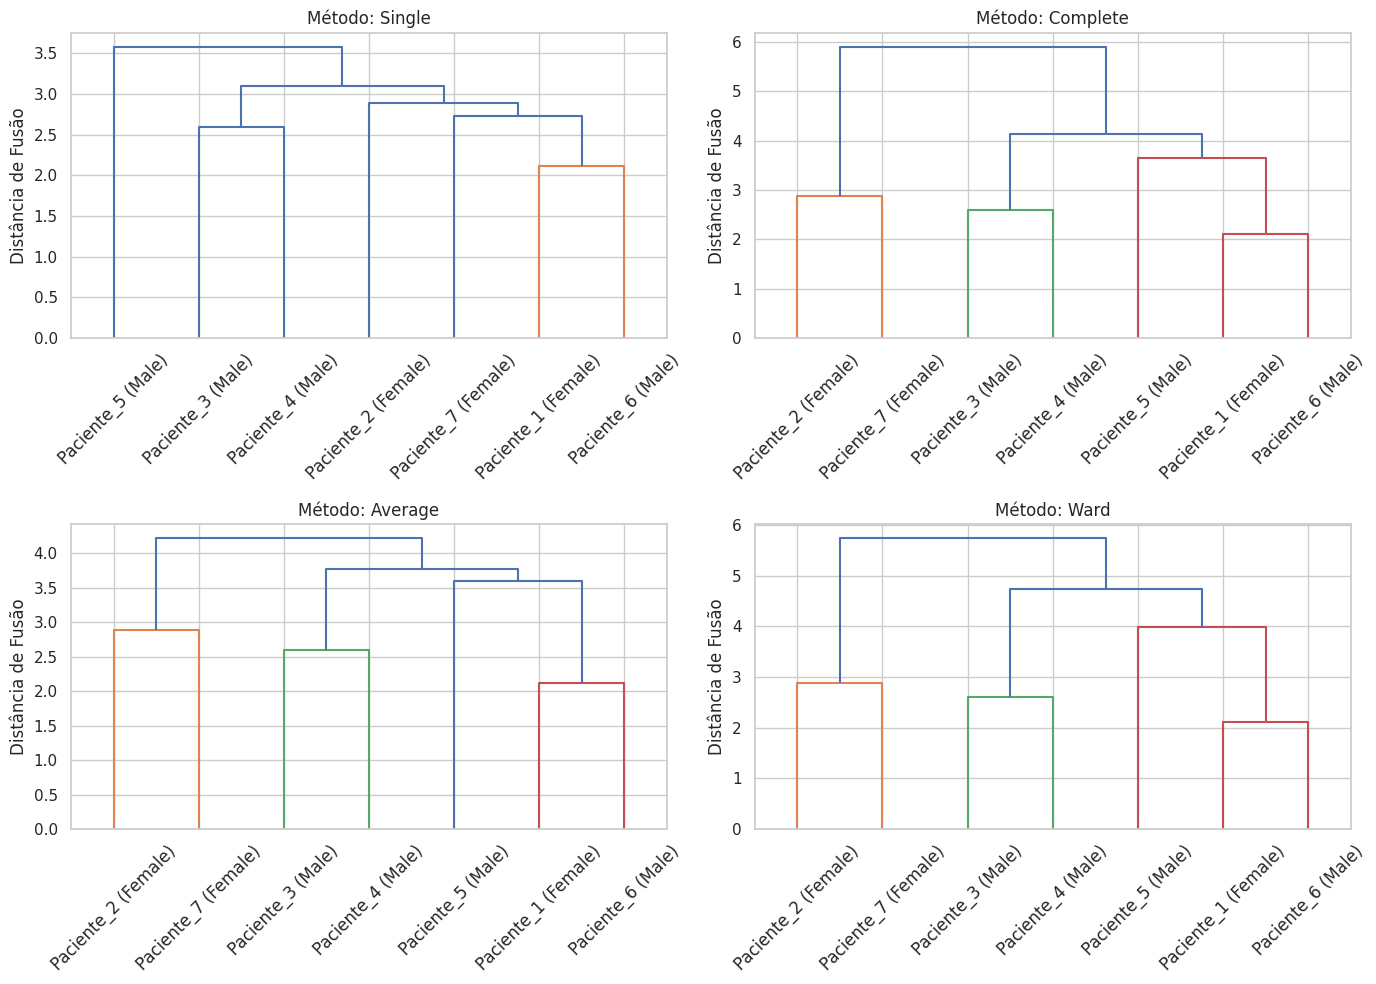

In [ ]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist

# 1. Separando os 7 pacientes para manter a coerência visual com a sua análise
df_amostra = df_padronizado.iloc[:7]

# 2. Calculando o vetor de distâncias para a amostra
distancias_amostra = pdist(df_amostra, metric='euclidean')

# 3. Definindo os métodos solicitados
metodos_ligacao = ['single', 'complete', 'average', 'ward']

# 4. Plotando os dendrogramas para comparar os métodos
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

for i, metodo in enumerate(metodos_ligacao):
    # A função linkage constrói a hierarquia dos clusters
    matriz_hierarquia = linkage(distancias_amostra, method=metodo)

    dendrogram(
        matriz_hierarquia,
        labels=df_amostra.index.values,
        leaf_rotation=45, # Adicionado para os nomes não ficarem sobrepostos
        ax=axes[i]
    )

    axes[i].set_title(f'Método: {metodo.capitalize()}')
    axes[i].set_ylabel('Distância de Fusão')

plt.tight_layout()
plt.show()

#### Análise

Analisando os dendrogramas dos quatro métodos, observamos o seguinte: o método Single é o único que apresenta uma formação de grupos diferente em sua sequência de junções. Já os demais métodos possuem um padrão de estrutura idêntico, havendo uma semelhança muito grande entre o Complete e o Ward, inclusive em suas distâncias de fusão. Com base nesse padrão estrutural consistente, os pacientes se correlacionam formando os mesmos agrupamentos iniciais: o Paciente 1 se une ao 6, o Paciente 3 ao 4, e o Paciente 2 ao 7, com o Paciente 5 se anexando posteriormente ao grupo formado pelos pacientes 1 e 6.

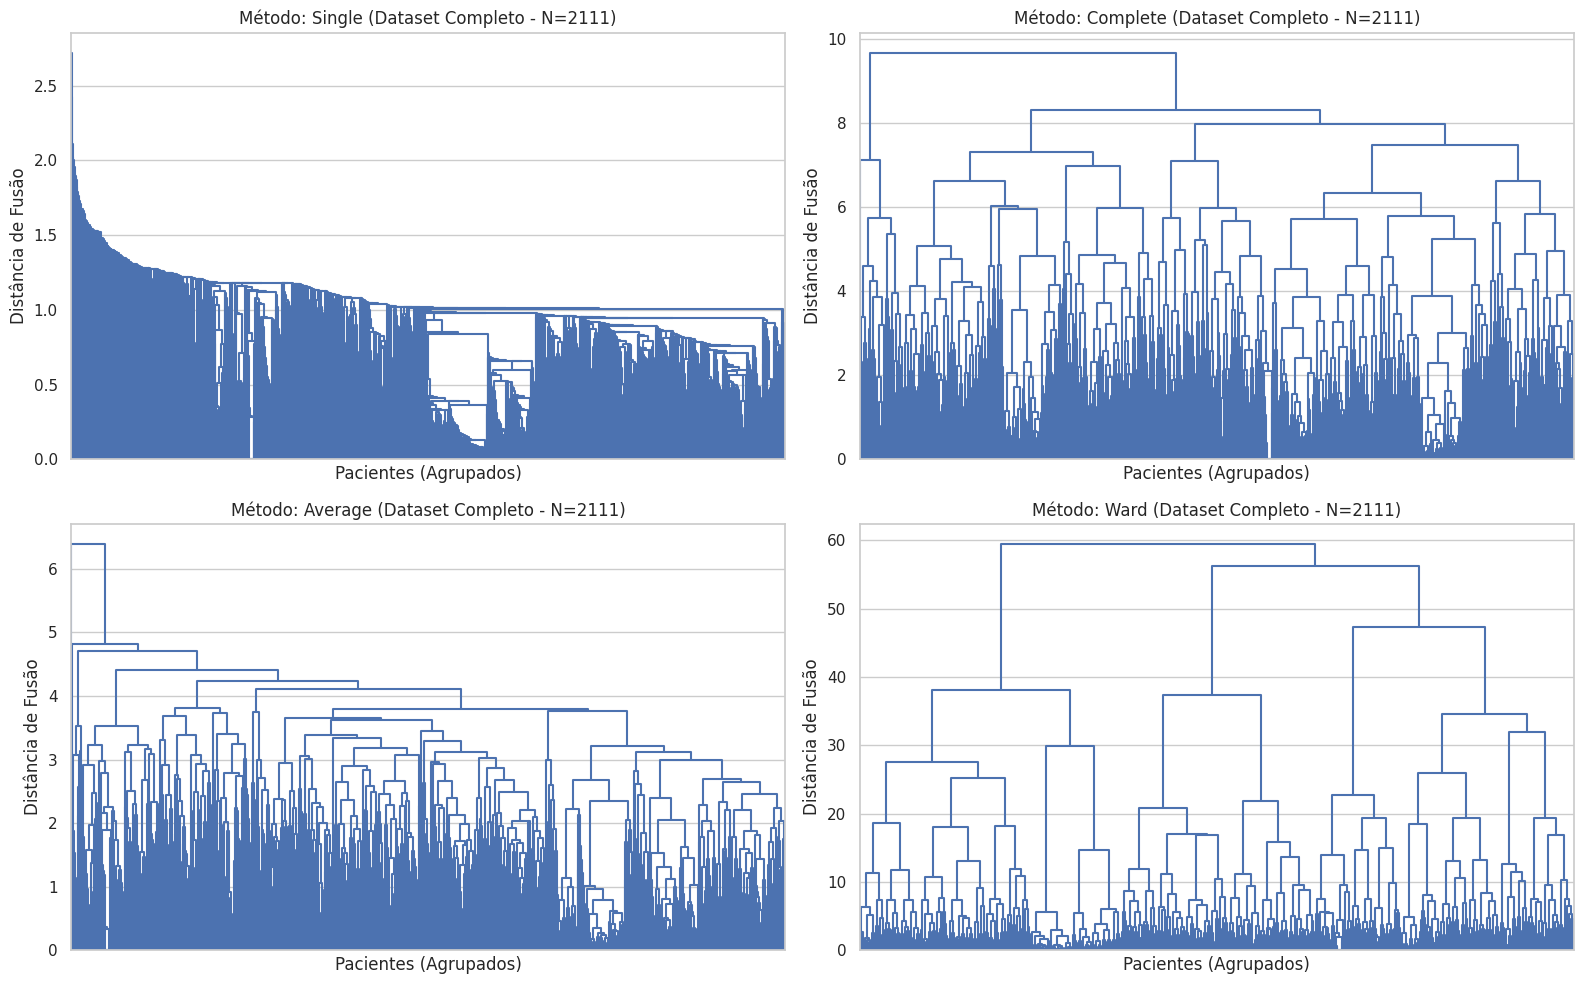

In [ ]:
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.spatial.distance import pdist

# 1. Calculando a matriz de distâncias na base completa (2.111 linhas)
distancias_completa = pdist(df_padronizado, metric='euclidean')

# 2. Definindo os 4 métodos de ligação
metodos_ligacao = ['single', 'complete', 'average', 'ward']

# 3. Plotando os dendrogramas para comparação dos métodos
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, metodo in enumerate(metodos_ligacao):
    # Constrói a hierarquia de clusters para a base inteira
    matriz_hierarquia = linkage(distancias_completa, method=metodo)

    dendrogram(
        matriz_hierarquia,
        no_labels=True,  # Remove os rótulos do eixo X para evitar poluição visual com 2.111 linhas
        color_threshold=0,  # Mantém a estrutura com cor única ou padrão
        ax=axes[i]
    )

    axes[i].set_title(f'Método: {metodo.capitalize()} (Dataset Completo - N=2111)')
    axes[i].set_xlabel('Pacientes (Agrupados)')
    axes[i].set_ylabel('Distância de Fusão')

plt.tight_layout()
plt.show()

### 📊 Análise Comparativa dos Métodos de Ligação Hierárquica (Dataset Completo)

---

#### 📌 **Método Single (Vizinho Mais Próximo)**
* **Comportamento:** Apresenta a menor distância de fusão máxima da base, alcançando o limite de aproximadamente 2.75[cite: 3].
* **Interpretação:** Demonstra forte efeito de "encadeamento", fundindo os 2.111 registros de forma contínua com distâncias mínimas, o que inviabiliza a identificação de grupos isolados e bem definidos.

#### 📌 **Método Average (Média das Distâncias)**
* **Comportamento:** Atinge uma distância de fusão máxima próxima a 6.75[cite: 3].
* **Interpretação:** Gera uma estrutura levemente mais equilibrada que o método Single, mas ainda mantém agrupamentos densos e com pouca separação visual nas camadas superiores.

#### 📌 **Método Complete (Vizinho Mais Distante)**
* **Comportamento:** Apresenta um ganho de escala visível, chegando a quase 10 na distância máxima de fusão[cite: 3].
* **Interpretação:** Força a criação de clusters esféricos e mais compactos, resultando em uma ramificação superior muito mais clara que os dois métodos anteriores.

#### 📌 **Método Ward (Minimização da Variância)**
* **Comportamento:** Destaca-se pela maior distância de fusão absoluta do painel, encostando no patamar de 60[cite: 3].
* **Interpretação:** Assim como observado na amostra reduzida, o Ward confirma-se como o método mais robusto para separar a base completa. Ao focar na minimização da variância interna, ele cria troncos principais altamente isolados, facilitando a decisão de corte (K) baseada nos saltos de distância.

### 3.1 Como saber qual Dendograma é o melhor matemático?

Utilizamos o **Coeficiente Cofenético**. Ele mede o quanto a hierarquia montada preserva as distâncias originais daquela matriz que vimos no Passo 1. Quanto mais próximo de 1, melhor.

In [ ]:
print("=== Coeficiente Cofenético por Método ===")
for metodo in metodos_ligacao:
    matriz_hierarquia = linkage(distancias_amostra, method=metodo)
    coeficiente, _ = cophenet(matriz_hierarquia, distancias_amostra)
    print(f"Método {metodo.ljust(10)}: {coeficiente:.3f}")

=== Coeficiente Cofenético por Método ===
Método single    : 0.619
Método complete  : 0.630
Método average   : 0.679
Método ward      : 0.667


In [ ]:
from scipy.cluster.hierarchy import linkage, cophenet

print("=== Coeficiente Cofenético por Método (Dataset Completo) ===")
for metodo in metodos_ligacao:
    # Aplicando o linkage na matriz de distâncias da base inteira
    matriz_hierarquia = linkage(distancias_completa, method=metodo)

    # Calculando a correlação cofenética para a base inteira
    coeficiente, _ = cophenet(matriz_hierarquia, distancias_completa)

    print(f"Método {metodo.ljust(10)}: {coeficiente:.3f}")

=== Coeficiente Cofenético por Método (Dataset Completo) ===
Método single    : 0.469
Método complete  : 0.463
Método average   : 0.581
Método ward      : 0.406


### 4 - Escolhendo o Número Ideal de Clusters (O Método do Cotovelo)

Não basta agrupar, precisamos saber onde "cortar a árvore" (dendrograma).
O **Método do Cotovelo (Elbow)** plota o erro (variância dentro dos grupos) em relação ao número de clusters. Onde o gráfico forma uma "quina" ou desacelera abruptamente, temos uma sugestão de K ótimo.

/usr/local/lib/python3.13/dist-packages/numpy/_core/fromnumeric.py:81: FutureWarning:

The behavior of DataFrame.sum with axis=None is deprecated, in a future version this will reduce over both axes and return a scalar. To retain the old behavior, pass axis=0 (or do not pass axis)



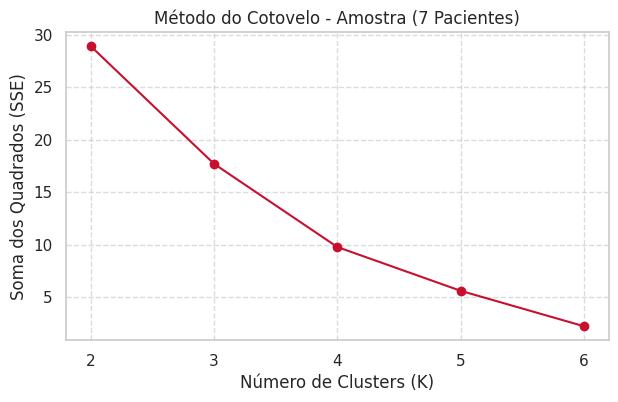

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import pdist

# 1. Isolando os 7 pacientes e recalculando a distância condensada para eles
df_amostra = df_padronizado.iloc[:7]
distancias_amostra = pdist(df_amostra, metric='euclidean')

def calcular_sse_hierarquico(df, matriz_distancias_condensada, max_k):
    """Calcula o Erro Quadrático Soma (SSE) para diferentes cortes K."""
    sse_lista = []
    k_valores = range(2, max_k + 1)

    # Utilizando o método Ward
    matriz_hierarquia = linkage(matriz_distancias_condensada, method='ward')

    for k in k_valores:
        labels = fcluster(matriz_hierarquia, k, criterion='maxclust')
        sse = 0
        for label_unico in np.unique(labels):
            dados_cluster = df[labels == label_unico]
            centroide = dados_cluster.mean()
            sse += np.sum((dados_cluster - centroide)**2).sum()
        sse_lista.append(sse)

    return k_valores, sse_lista

# 2. Aplicando a função na amostra (max_k = 6)
k_vals, sse_vals = calcular_sse_hierarquico(df_amostra, distancias_amostra, max_k=len(df_amostra)-1)

# 3. Plotagem do gráfico
plt.figure(figsize=(7, 4))
plt.plot(k_vals, sse_vals, marker='o', color='#C8102E')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Soma dos Quadrados (SSE)')
plt.title('Método do Cotovelo - Amostra (7 Pacientes)')
plt.xticks(k_vals)
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

### 4.1 Interpretando os Grupos Finais

Pelo Cotovelo, percebemos que **K=4** é um bom número. Vamos atribuir cada aluno ao seu grupo e plotar visualmente.

=== Perfil Médio de Cada Cluster (Valores Originais) ===


,Height,Weight
Cluster,,
1,1.51,55.50
2,1.80,82.00
3,1.62,58.50
4,1.78,89.80


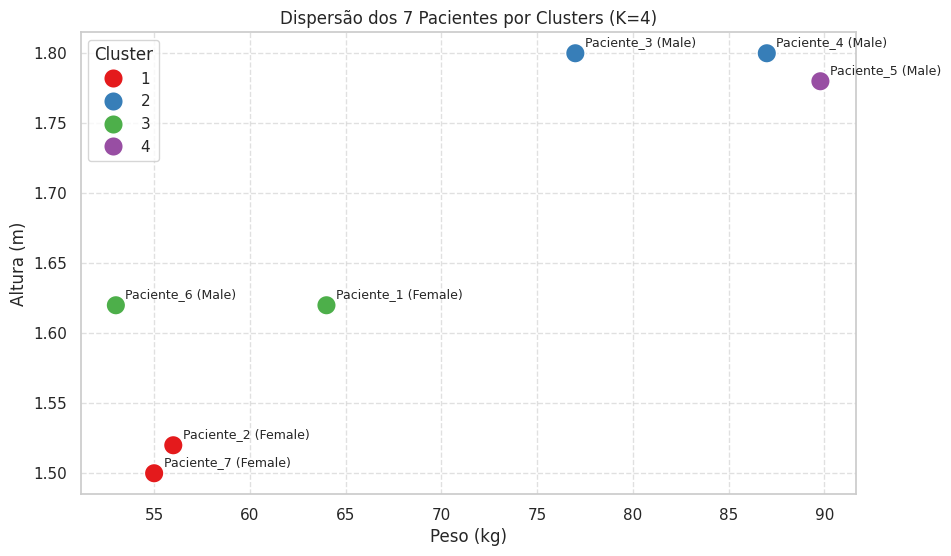

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, fcluster

# 1. Cortando o dendrograma (usando o método ward) para gerar 4 clusters na amostra
matriz_hierarquia = linkage(distancias_amostra, method='ward')
labels_finais = fcluster(matriz_hierarquia, t=4, criterion='maxclust')

# 2. Selecionando a amostra e garantindo a conversão de Weight e Height para numérico
df_amostra_final = df.iloc[:7].copy()

# Converte Weight e Height explicitamente para float para evitar que sejam descartadas
df_amostra_final['Weight'] = pd.to_numeric(df_amostra_final['Weight'], errors='coerce')
df_amostra_final['Height'] = pd.to_numeric(df_amostra_final['Height'], errors='coerce')

df_amostra_final.index = df_amostra.index
df_amostra_final['Cluster'] = labels_finais

# 3. Resumo estatístico do Perfil de cada Cluster
print("=== Perfil Médio de Cada Cluster (Valores Originais) ===")
display(df_amostra_final.groupby('Cluster').mean(numeric_only=True).round(2))

# 4. Visualização no Plano Cartesiano (Peso vs Altura)
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df_amostra_final,
    x='Weight',
    y='Height',
    hue='Cluster',
    palette='Set1',
    s=200
)

# Adicionando os rótulos aos pontos do gráfico
for nome, row in df_amostra_final.iterrows():
    plt.text(row['Weight'] + 0.5, row['Height'] + 0.005, nome, fontsize=9)

plt.title('Dispersão dos 7 Pacientes por Clusters (K=4)')
plt.xlabel('Peso (kg)')
plt.ylabel('Altura (m)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

#### Análise: Aqui se confirma exatamente o que vimos no dendrograma para $K=4$:

**1. Cluster 1 (Vermelho):** Formado pelos Pacientes 2 e 7, que possuem alta similaridade entre si, estando muito próximos tanto em peso quanto em altura.   
**2. Cluster 3 (Verde):** Formado pelos Pacientes 1 e 6, que apresentam grande similaridade de altura (aproximadamente 1,62 m), variando apenas no peso.   
**3. Cluster 2 (Azul):** Formado pelos Pacientes 3 e 4, que compartilham praticamente a mesma altura (1,80 m), mas com pesos distintos.   
**4. Cluster 4 (Roxo):** Formado isoladamente pelo Paciente 5, que cria um grupo próprio por estar em um ponto intermediário de variância, situando-se próximo ao Paciente 4 e também ao Paciente 3 no espaço bidimensional.

### 5 - Cluster Não Hierárquico: K-Means (Dataset Complete de Obesidade)

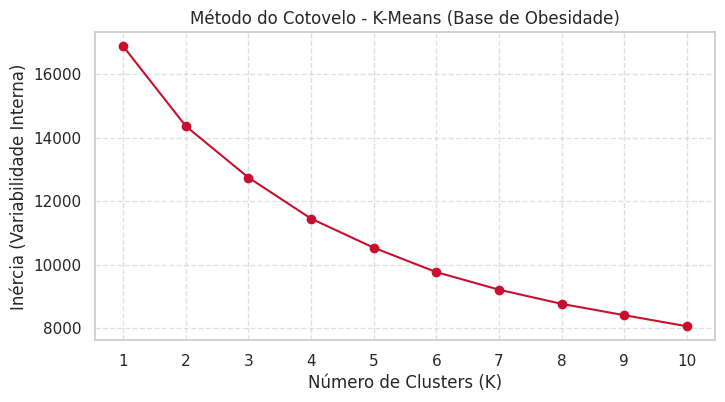

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# Função para encontrar o K ótimo usando a Inércia do K-Means
def plotar_cotovelo_kmeans(dados_padronizados, max_k=10):
    inercia = []
    k_valores = range(1, max_k + 1)

    for k in k_valores:
        # n_init=10 evita que o algoritmo fique preso em mínimos locais
        modelo = KMeans(n_clusters=k, random_state=42, n_init=10)
        modelo.fit(dados_padronizados)
        inercia.append(modelo.inertia_)

    plt.figure(figsize=(8, 4))
    plt.plot(k_valores, inercia, marker='o', color='#C8102E')
    plt.xlabel('Número de Clusters (K)')
    plt.ylabel('Inércia (Variabilidade Interna)')
    plt.title('Método do Cotovelo - K-Means (Base de Obesidade)')
    plt.xticks(k_valores)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.show()

# Rodando na base completa de 2.111 pacientes padronizada (Z-Score)
plotar_cotovelo_kmeans(df_padronizado)

#### Análise: Definição do valor de K

*Com base no gráfico do Método do Cotovelo para o K-Means, observamos que o número ideal de clusters se situa no intervalo entre $K=5$ e $K=6$.   A decisão final pelo valor de $K=6$ se justifica por dois fatores centrais:*

1. **Redução Substancial da Inércia:** Em $K=6$, a variabilidade interna do modelo atinge um nível consideravelmente baixo (abaixo de 10.000).   

2. **Ponto de Estabilização:** O ponto $K=6$ representa a última inflexão relevante (o 'último curvamento') da curva. A partir dele, a linha assume uma trajetória linear contínua e suave, indicando que adicionar novos clusters ($K \ge 7$) traz ganhos irrisórios de ganho de informação em relação ao aumento de complexidade do modelo.

### 5.1 Rodando o K-Means com K = 4, 5 e 6


In [49]:
import pandas as pd
from sklearn.cluster import KMeans

# 1. Definindo K=5 com base na análise do cotovelo
k_escolhido = 4
kmeans = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)

# 2. Ajustando o modelo e prevendo os clusters nos dados padronizados
labels_kmeans = kmeans.fit_predict(df_padronizado)

# 3. Adicionando a coluna do Cluster à base original com valores não padronizados
df_final = df.copy()

# Garantindo que todas as colunas possíveis sejam convertidas para formato numérico
for col in df_final.columns:
    df_final[col] = pd.to_numeric(df_final[col], errors='ignore')

df_final['Cluster'] = labels_kmeans

# 4. Distribuição dos pacientes pelos 5 clusters
print("=== Quantidade de Pacientes por Cluster (K=5) ===")
print(df_final['Cluster'].value_counts().sort_index())

# 5. Perfil Médio de cada um dos 5 clusters (variáveis numéricas reais - Parêntese corrigido)
print("\n=== Perfil Médio por Cluster (Valores Originais) ===")
display(df_final.groupby('Cluster').mean(numeric_only=True).round(2))

=== Quantidade de Pacientes por Cluster (K=5) ===
Cluster
0    492
1    335
2    695
3    589
Name: count, dtype: int64

=== Perfil Médio por Cluster (Valores Originais) ===


/tmp/ipykernel_2310/2860590053.py:16: FutureWarning:

errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead



,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Cluster,,,,,,,,
0,30.94,1.66,94.29,2.61,2.89,1.92,0.44,0.31
1,22.89,1.63,71.75,2.36,1.17,1.90,0.77,0.64
2,20.44,1.68,66.08,2.24,3.11,1.88,1.21,0.90
3,24.16,1.80,112.79,2.51,2.88,2.30,1.39,0.67


#### 📌 **Análise do Cenário K=4**
No corte **K=4**, o **cluster 2** concentra a maior quantidade de pacientes (695 indivíduos). Este grupo apresenta uma idade média de 20,44 anos, altura de 1,68 m e peso de 66,08 kg. Analisando os seus hábitos, nota-se que é o perfil com a menor média de consumo de vegetais (2,24) e de água (1,48). Por outro lado, lidera o número de refeições principais diárias (3,11) e o tempo de uso de telas. A frequência de atividade física (FAF) é de 1,21, ficando atrás apenas do cluster 3.

Já o **cluster 3** (segundo maior grupo, com 589 pessoas) apresenta uma idade média de 24,16 anos, altura de 1,80 m e peso elevado de 112,79 kg. Em termos comportamentais, destaca-se pelo maior consumo de água da base (2,30) e pela maior frequência de atividade física, ocupando também o segundo lugar no consumo de vegetais (2,51) e no uso de telas (0,67).

**Interpretação:** Esses dois grupos chamam a atenção por serem os mais populosos e por apresentarem hábitos muito distintos. Observa-se claramente como as variáveis comportamentais e físicas estão fortemente correlacionadas na definição dos perfis.


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

# 1. Definindo K=5 com base na análise do cotovelo
k_escolhido = 5
kmeans = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)

# 2. Ajustando o modelo e prevendo os clusters nos dados padronizados
labels_kmeans = kmeans.fit_predict(df_padronizado)

# 3. Adicionando a coluna do Cluster à base original com valores não padronizados
df_final = df.copy()

# Garantindo que todas as colunas possíveis sejam convertidas para formato numérico
for col in df_final.columns:
    df_final[col] = pd.to_numeric(df_final[col], errors='ignore')

df_final['Cluster'] = labels_kmeans

# 4. Distribuição dos pacientes pelos 5 clusters
print("=== Quantidade de Pacientes por Cluster (K=5) ===")
print(df_final['Cluster'].value_counts().sort_index())

# 5. Perfil Médio de cada um dos 5 clusters (variáveis numéricas reais - Parêntese corrigido)
print("\n=== Perfil Médio por Cluster (Valores Originais) ===")
display(df_final.groupby('Cluster').mean(numeric_only=True).round(2))

=== Quantidade de Pacientes por Cluster (K=5) ===
Cluster
0    295
1    618
2    480
3    416
4    302
Name: count, dtype: int64

=== Perfil Médio por Cluster (Valores Originais) ===


/tmp/ipykernel_1149/1681140559.py:16: FutureWarning:

errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead



,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Cluster,,,,,,,,
0,36.52,1.68,86.06,2.36,2.52,1.80,0.94,0.20
1,24.54,1.75,117.43,2.65,2.94,2.28,0.86,0.59
2,21.32,1.67,71.12,2.17,3.04,1.60,0.55,0.84
3,20.70,1.73,70.02,2.43,3.13,2.29,2.04,0.85
4,21.64,1.63,71.37,2.37,1.17,1.92,0.71,0.69


#### 📌 **Análise do Cenário K=5**
Avançando para o cenário **K=5**, a ordem dos grupos sofre alterações, mas a lógica estrutural se mantém. O **cluster 1**, que passa a ser o mais populoso (618 pessoas), registra idade média de 24,54 anos, altura de 1,75 m e peso de 117,43 kg. O perfil de hábitos também se ajusta: este grupo lidera o consumo de vegetais (2,65), fica em segundo lugar no consumo de água (2,28) e em terceiro nas refeições principais (2,94). A atividade física cai para 0,86, enquanto o tempo de tela é o menor de toda a amostra (0,59).

**Interpretação:** Os dados evidenciam que o conjunto de hábitos diários, alinhado à estatura dos indivíduos, justifica a consolidação e a manutenção dessa faixa de peso mais elevada.


In [ ]:
import pandas as pd
from sklearn.cluster import KMeans

# 1. Definindo K=6 com base na análise do cotovelo
k_escolhido = 6
kmeans = KMeans(n_clusters=k_escolhido, random_state=42, n_init=10)

# 2. Ajustando o modelo e prevendo os clusters nos dados padronizados
labels_kmeans = kmeans.fit_predict(df_padronizado)

# 3. Adicionando a coluna do Cluster à base original com valores não padronizados
df_final = df.copy()

# Garantindo que todas as colunas possíveis sejam convertidas para formato numérico
for col in df_final.columns:
    df_final[col] = pd.to_numeric(df_final[col], errors='ignore')

df_final['Cluster'] = labels_kmeans

# 4. Distribuição dos pacientes pelos 6 clusters
print("=== Quantidade de Pacientes por Cluster (K=6) ===")
print(df_final['Cluster'].value_counts().sort_index())

# 5. Perfil Médio de cada um dos 6 clusters (variáveis numéricas reais - Parêntese corrigido)
print("\n=== Perfil Médio por Cluster (Valores Originais) ===")
display(df_final.groupby('Cluster').mean(numeric_only=True).round(2))

=== Quantidade de Pacientes por Cluster (K=6) ===
Cluster
0    287
1    465
2    382
3    391
4    305
5    281
Name: count, dtype: int64

=== Perfil Médio por Cluster (Valores Originais) ===


/tmp/ipykernel_1149/2934847653.py:16: FutureWarning:

errors='ignore' is deprecated and will raise in a future version. Use to_numeric without passing `errors` and catch exceptions explicitly instead



,Age,Height,Weight,FCVC,NCP,CH2O,FAF,TUE
Cluster,,,,,,,,
0,21.61,1.63,69.94,2.37,1.16,1.92,0.68,0.68
1,24.32,1.80,120.10,2.51,2.84,2.22,1.19,0.67
2,20.58,1.73,68.96,2.50,3.14,2.28,2.09,0.83
3,21.14,1.68,70.80,1.91,3.01,1.69,0.62,0.98
4,24.14,1.64,94.26,2.95,3.03,2.04,0.30,0.43
5,36.74,1.67,85.73,2.34,2.54,1.80,0.91,0.19


#### 📌 **Análise do Cenário K=6**
No agrupamento **K=6**, a comparação direta entre o **cluster 4** e o **cluster 1** revela perfis muito próximos em termos de IMC (médias de 37 e 35, respectivamente), colocando ambos em faixas de peso crítico. Além da semelhança corporal, os dois grupos compartilham hábitos alimentares muito parecidos.

A principal distinção está na mobilidade: enquanto o cluster 4 apresenta uma frequência de atividade física quase nula (0,30), o cluster 1 atinge 1,19.

**Interpretação:** Essa disparidade sugere que os indivíduos do cluster 1, mesmo enfrentando um cenário crítico de peso, ainda buscam manter algum nível de cuidado com a saúde através do exercício. Em contrapartida, o cluster 4 reflete um perfil de maior inércia física, indicando um agravamento da condição pela total ausência de engajamento em atividades.

#### 📊 Análise Comparativa dos Cenários de Agrupamento (K=4, K=5 e K=6)

---


#### 💡 **Conclusão Geral (K=4, K=5 e K=6)**
Avaliando a evolução entre os três cenários, nota-se a consistência de um padrão muito claro (representado, por exemplo, pelo cluster 1 nos cortes finais): trata-se de um grupo de jovens (entre 24 e 25 anos) com estatura média de 1,78 m e uma amplitude de peso muito alta, variando entre 112 kg e 120 kg.

A característica central que une esses perfis em todos os cortes é o descompasso entre um consumo alimentar diário excessivo e uma baixa frequência de exercícios. A análise de dados corrobora que a reversão desse nível de obesidade passa, fundamentalmente, pela redução no volume de refeições aliada ao aumento da atividade física, permitindo que o corpo se adapte a uma proporção mais saudável.